In [ ]:
import os
from typing import Annotated, Sequence, TypedDict
from langchain_classic.agents import Tool
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.document_loaders import WebBaseLoader, ArxivLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langgraph.prebuilt import create_react_agent
from langgraph.graph import StateGraph, END
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from langchain_community.document_loaders import TextLoader


USER_AGENT environment variable not set, consider setting it to identify your requests.


In [3]:
!ollama pull deepseek-v2

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                         
pulling 19f2fb9e8bc6: 100% ▕██████████████████▏   32 B                         
pulling 2b2c35718a16: 100% ▕██████████████████▏  494 B                         
verifying sha256 digest 
writing manifest 
removing unused layers ⠋ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB       

In [38]:
from dotenv import load_dotenv
from langchain_ollama import ChatOllama
load_dotenv()
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")
from langchain.chat_models import init_chat_model
llm = init_chat_model(
    "gemini-3.1-flash-lite",
    model_provider="google_genai",
    temperature=0.2
)

In [40]:
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6', 'langchain-google-genai': '4.4.2'}}, profile={'name': 'Gemini 3.1 Flash Lite', 'release_date': '2026-05-07', 'last_updated': '2026-05-07', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.1-flash-lite', temperature=0.2, client=<google.genai.client.Client object at 0x00000247552E03E0>, default_metadata=(), model_kwar

In [41]:
from torch import embedding
def make_retriever_tool_from_text(file, name, desc):

    docs = TextLoader(file, encoding="utf-8").load()

    chunks = RecursiveCharacterTextSplitter(
        chunk_size=500,
        chunk_overlap=50
    ).split_documents(docs)
    embeddings=HuggingFaceEmbeddings()
    vs = FAISS.from_documents(chunks, embeddings)

    retriever = vs.as_retriever(search_kwargs={"k": 3})

    def tool_func(query: str) -> str:

        print(f"📚 Using tool: {name}")

        results = retriever.invoke(query)

        return "\n\n".join(
            doc.page_content for doc in results
        ) or "No relevant documents found."

    return Tool(
        name=name,
        description=desc,
        func=tool_func
    )


# Wikipedia Tool
wiki_tool = Tool(
    name="Wikipedia",
    description="Use this tool to fetch general world knowledge from Wikipedia.",
    func=WikipediaQueryRun(
        api_wrapper=WikipediaAPIWrapper()
    ).run
)


# Arxiv Tool
def arxiv_search(query: str) -> str:

    print("🧪 Searching ArXiv...")

    results = ArxivLoader(
        query=query,
        load_max_docs=2
    ).load()

    return "\n\n".join(
        doc.page_content[:1000] for doc in results
    ) or "No papers found."


arxiv_tool = Tool(
    name="ArxivSearch",
    description="Use this tool to fetch academic research papers on technical topics.",
    func=arxiv_search
)


# Collect all tools


In [28]:
internal_tool_1=make_retriever_tool_from_text ( "sample_docs.txt",
    "InternalTechDocs",
    "Search internal tech documents for proprietary architecture and methods."
)
internal_tool_1

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 562.41it/s]


Tool(name='InternalTechDocs', description='Search internal tech documents for proprietary architecture and methods.', func=<function make_retriever_tool_from_text.<locals>.tool_func at 0x000002470AB0FCE0>)

In [29]:
internal_tool_2 = make_retriever_tool_from_text(
    "research_notes.txt",
    "InternalResearchNotes",
    "Search internal research notes for experimental results and agent designs."
)
internal_tool_2

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 619.92it/s]


Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results and agent designs.', func=<function make_retriever_tool_from_text.<locals>.tool_func at 0x000002470D940220>)

In [18]:
import uuid

In [31]:
import uuid
import builtins

builtins.uuid = uuid

In [47]:
from langgraph.prebuilt import create_react_agent

tools = [
    wiki_tool,
    internal_tool_1,
    internal_tool_2
]

react_node = create_react_agent(
    model=llm,
    tools=tools
)

print("✅ ReAct Agent created successfully!")

✅ ReAct Agent created successfully!


C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_25040\644756636.py:9: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  react_node = create_react_agent(


In [48]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

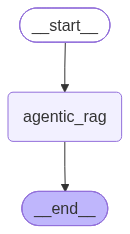

In [49]:
builder = StateGraph(AgentState)
builder.add_node("agentic_rag", react_node)
builder.set_entry_point("agentic_rag")
builder.add_edge("agentic_rag", END)

graph = builder.compile()
graph


In [51]:
query = "What do our internal research notes say about transformer variants, and what does ArXiv suggest recently?"

state = {
    "messages": [HumanMessage(content=query)]
}

result = graph.invoke(state)

answer = result["messages"][-1].content

# Extract clean text
if isinstance(answer, list):
    answer = "\n".join(
        item["text"]
        for item in answer
        if isinstance(item, dict) and item.get("type") == "text"
    )

print("\n" + "=" * 60)
print("🤖 FINAL ANSWER")
print("=" * 60)
print(answer)
print("=" * 60)

📚 Using tool: InternalResearchNotes

🤖 FINAL ANSWER
Based on our internal research notes and current trends in the field (as reflected in recent arXiv literature), here is a summary of transformer variants and their applications.

### Internal Research Notes Summary
Our internal experiments focus heavily on efficiency, deployment, and fine-tuning strategies for specific business use cases:

*   **Efficiency & Deployment:**
    *   **EfficientFormer:** Successfully deployed on edge devices (Raspberry Pi 4) with 92.4% accuracy on TinyImageNet; performs well with int8 quantization.
    *   **FlashAttention2:** Integrated into LLaMA2, resulting in a ~50% reduction in context latency.
    *   **TinyBERT:** Used for support ticket classification with an 87% F1 score, optimized with a 2-layer FFN adapter.
*   **Long-Context Handling:**
    *   **Longformer:** Tested on long-form logs (8192 tokens). While effective, it faces latency challenges (>1.2s per query), suggesting a need for further o